In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
from skimage import io, transform

In [ ]:
# === CONFIG ===
image_path = r".../Imaging data/Cropped_inner_well/AP00424_AnPY_K7 0124 AN_Pr3_24h_2x_3µmZ_XY01_CFW.tif" #Specify image path
RESIZE_SIZE = (1024, 1024)

# === LOAD 16-bit IMAGE ===
img = io.imread(image_path).astype(np.uint16)
print("Loaded:", img.shape, img.dtype, "min/max:", img.min(), img.max())

# Resize safely in 16-bit
img_resized = transform.resize(
    img, RESIZE_SIZE, order=1, preserve_range=True, anti_aliasing=True
).astype(np.uint16)

def visualize_aug(original, augmented, title):
    plt.figure(figsize=(8, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(original, cmap="gray")
    plt.title("Original")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(augmented, cmap="gray")
    plt.title(title)
    plt.axis("off")

    plt.tight_layout()
    plt.show()


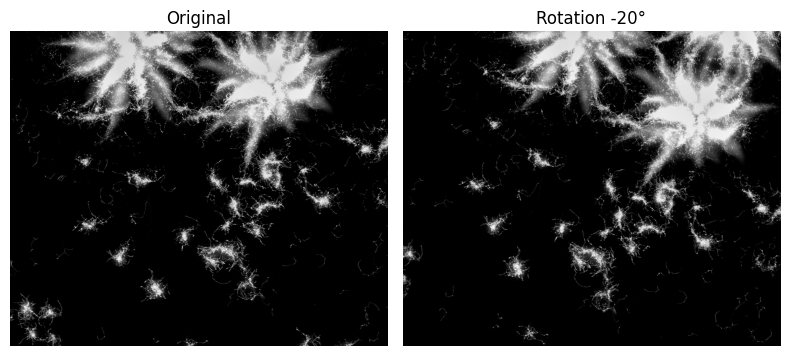

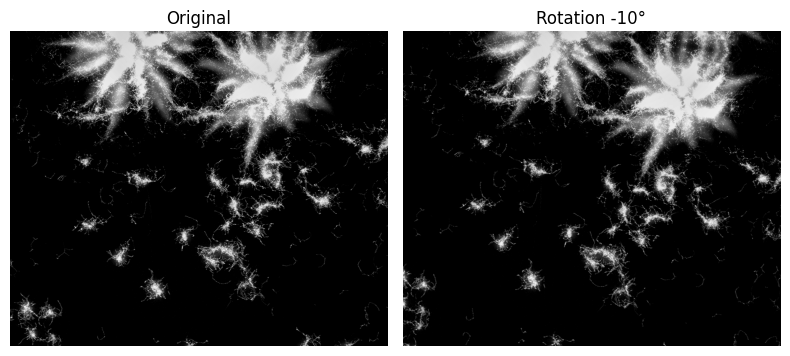

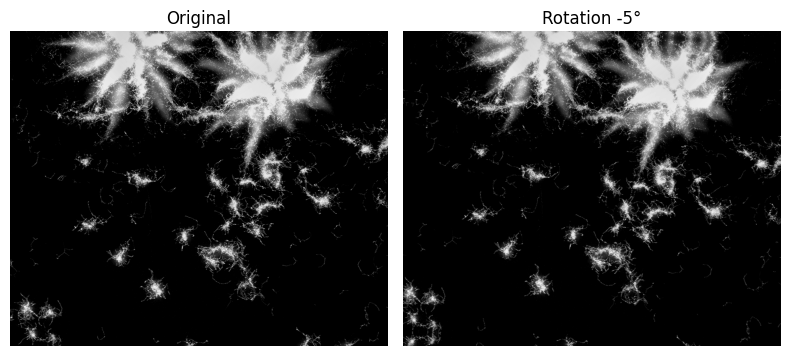

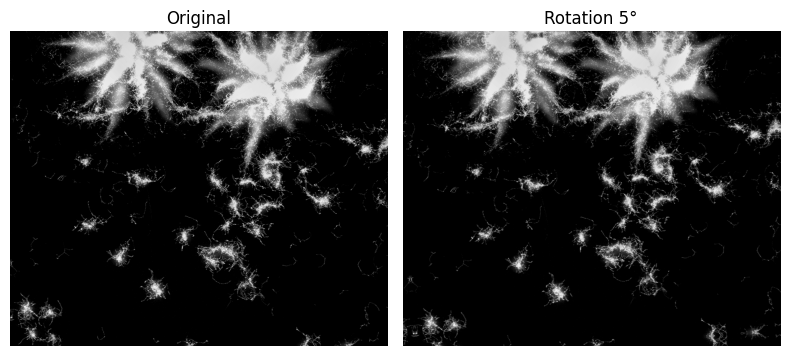

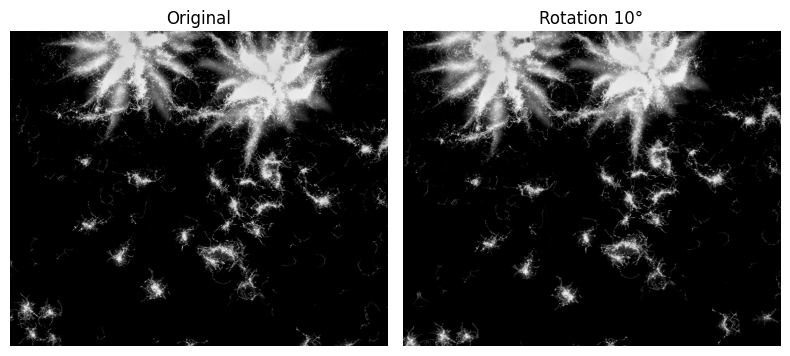

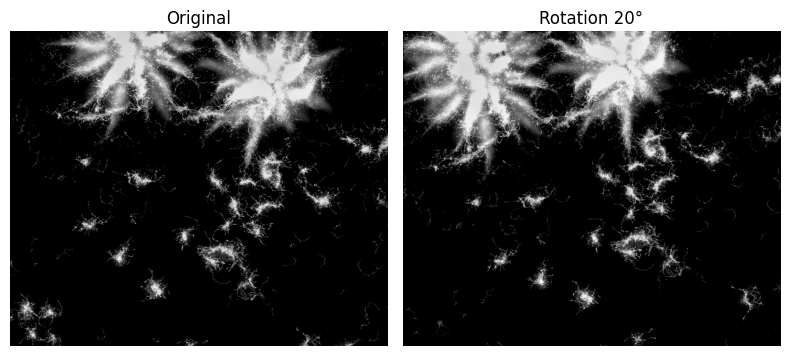

In [35]:
def aug_rotation(img, angle_deg):
    return transform.rotate(
        img.astype(np.float32),
        angle=angle_deg,
        resize=False,
        mode="reflect",
        preserve_range=True
    ).astype(np.uint16)

for angle in [-20, -10, -5, 5, 10, 20]:
    aug = aug_rotation(img, angle)
    visualize_aug(img, aug, f"Rotation {angle}°")


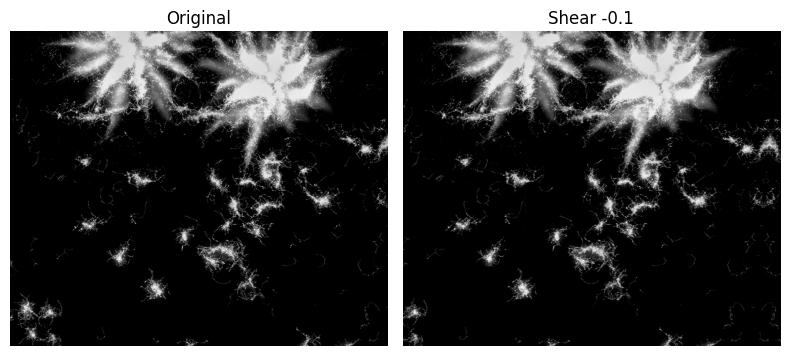

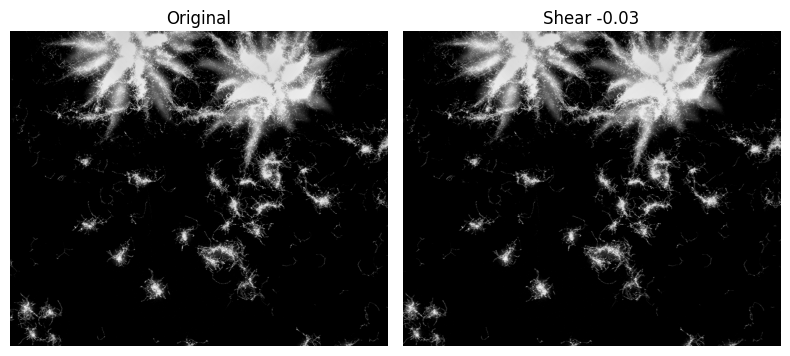

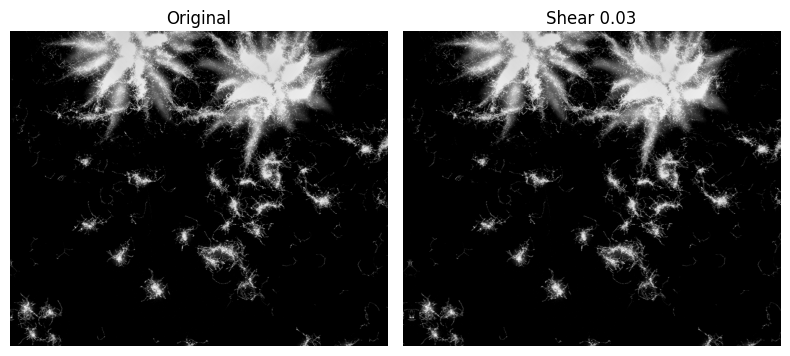

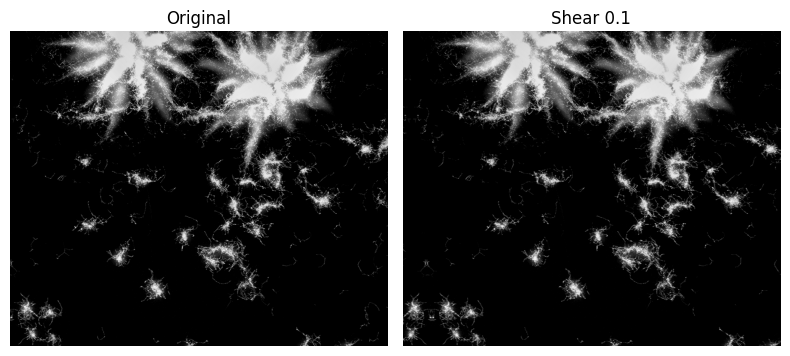

In [41]:
def aug_shear(img, shear):
    tform = transform.AffineTransform(shear=shear)
    return transform.warp(
        img.astype(np.float32),
        tform,
        mode="reflect",
        preserve_range=True
    ).astype(np.uint16)

for shear in [-0.10, -0.03, 0.03, 0.10]:
    aug = aug_shear(img, shear)
    visualize_aug(img, aug, f"Shear {shear}")


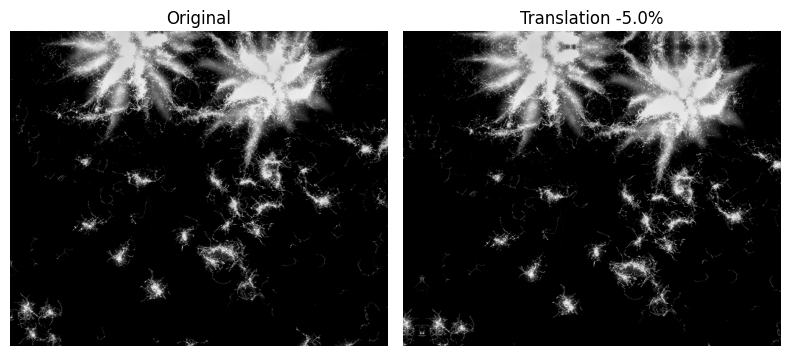

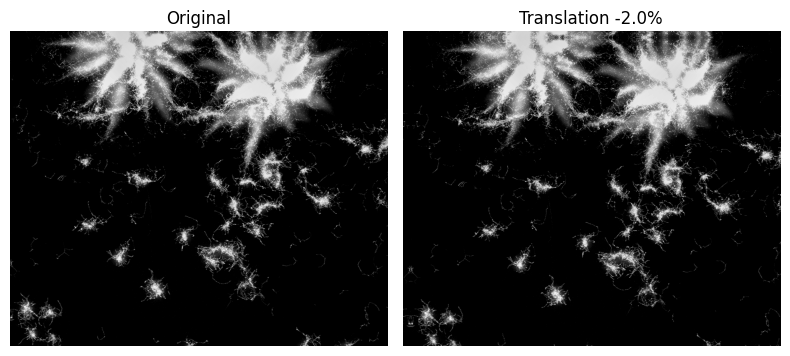

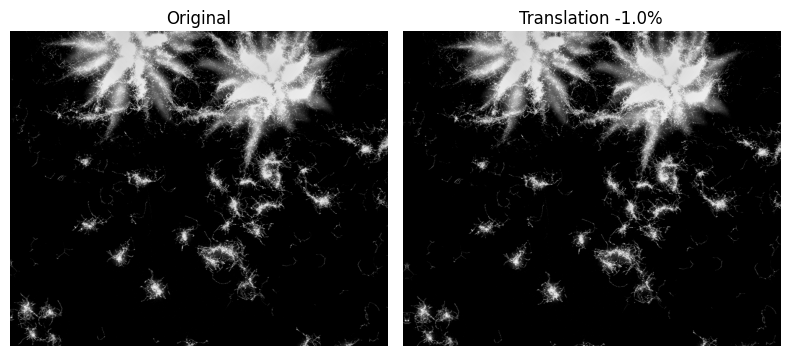

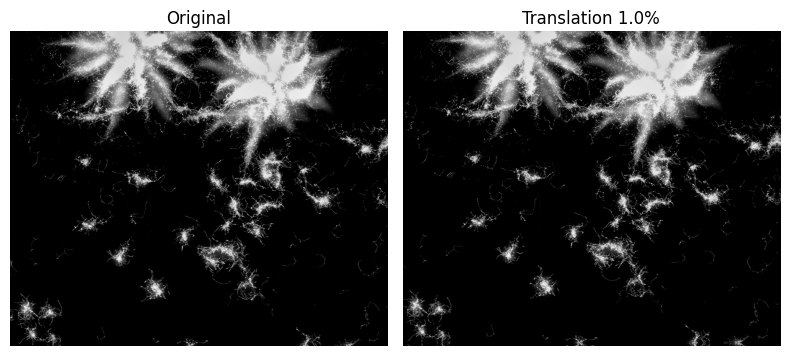

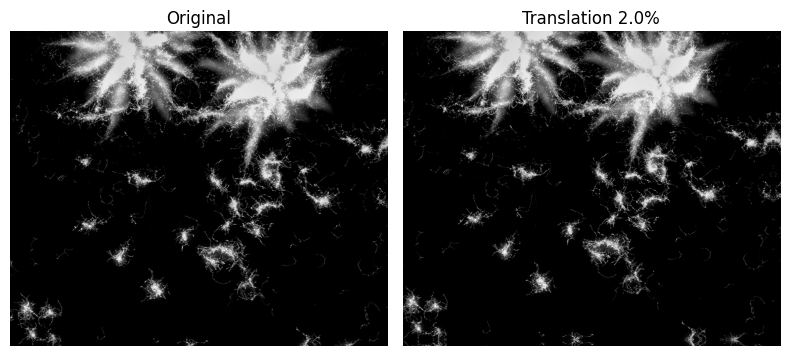

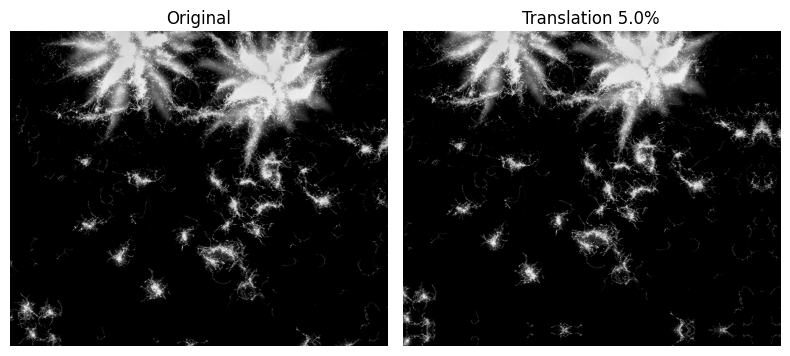

In [42]:
def aug_translation(img, tx_frac, ty_frac):
    tx = tx_frac * img.shape[1]
    ty = ty_frac * img.shape[0]
    tform = transform.AffineTransform(translation=(tx, ty))
    return transform.warp(
        img.astype(np.float32),
        tform,
        mode="reflect",
        preserve_range=True
    ).astype(np.uint16)

for t in [-0.05, -0.02, -0.01, 0.01, 0.02, 0.05]:
    aug = aug_translation(img, t, t)
    visualize_aug(img, aug, f"Translation {t*100:.1f}%")


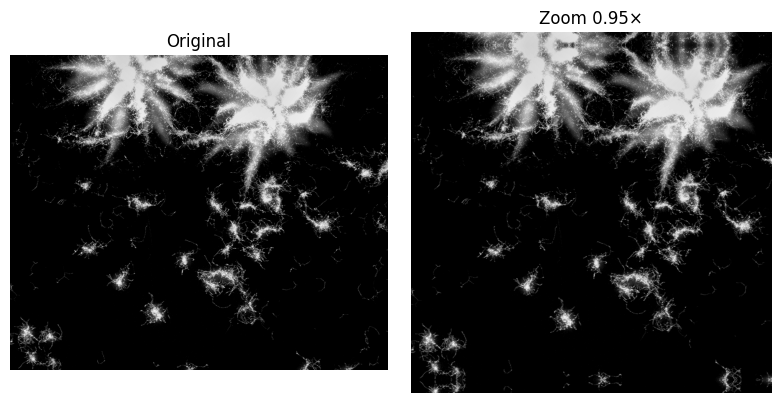

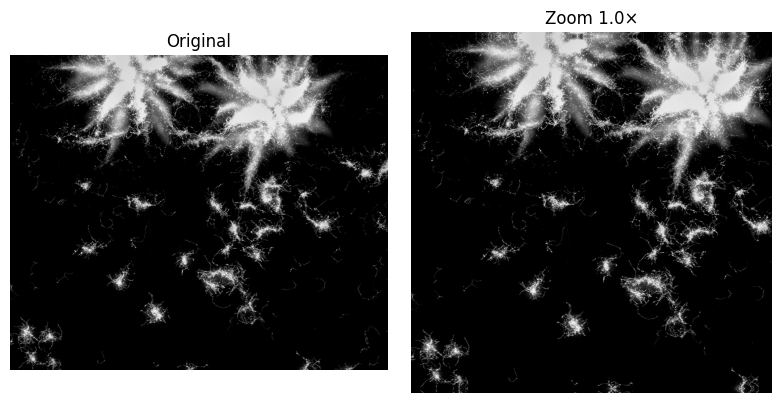

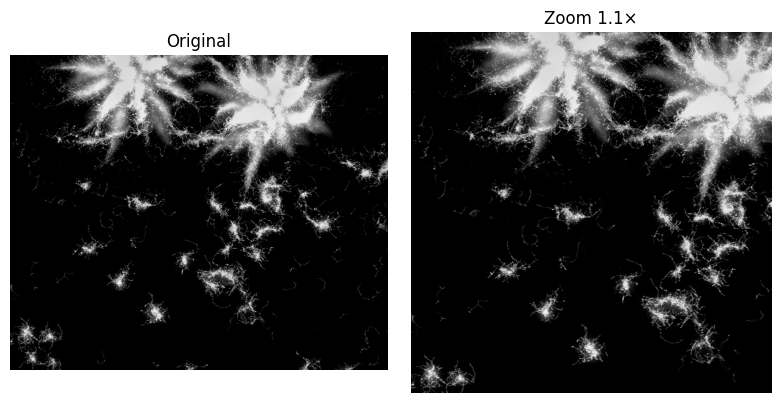

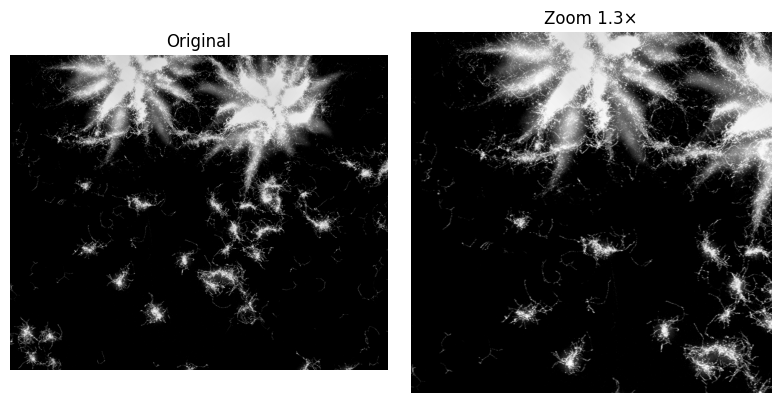

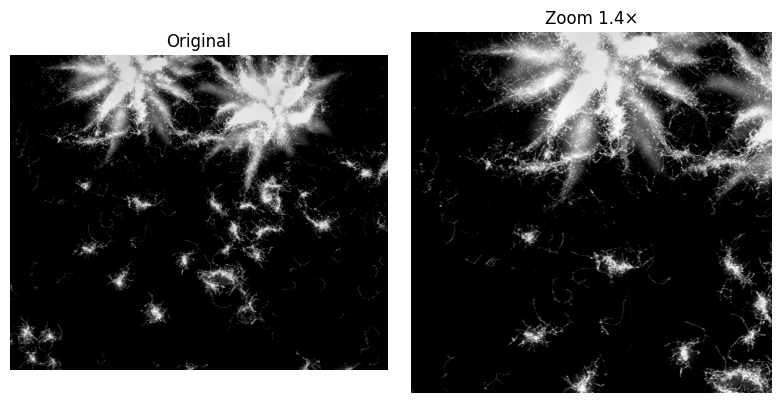

In [44]:
def aug_zoom(img, zoom):
    aug = transform.rescale(
        img.astype(np.float32),
        zoom,
        mode="reflect",
        preserve_range=True,
        anti_aliasing=True
    )

    h, w = aug.shape
    pad_y = max(0, RESIZE_SIZE[0] - h)
    pad_x = max(0, RESIZE_SIZE[1] - w)

    aug = np.pad(
        aug,
        ((pad_y//2, pad_y - pad_y//2),
         (pad_x//2, pad_x - pad_x//2)),
        mode="reflect"
    )

    return aug[:RESIZE_SIZE[0], :RESIZE_SIZE[1]].astype(np.uint16)

for z in [0.95, 1.0, 1.1, 1.3, 1.4]:
    aug = aug_zoom(img, z)
    visualize_aug(img, aug, f"Zoom {z}×")


Loaded: (1000, 1200) uint16 min/max: 0 44023


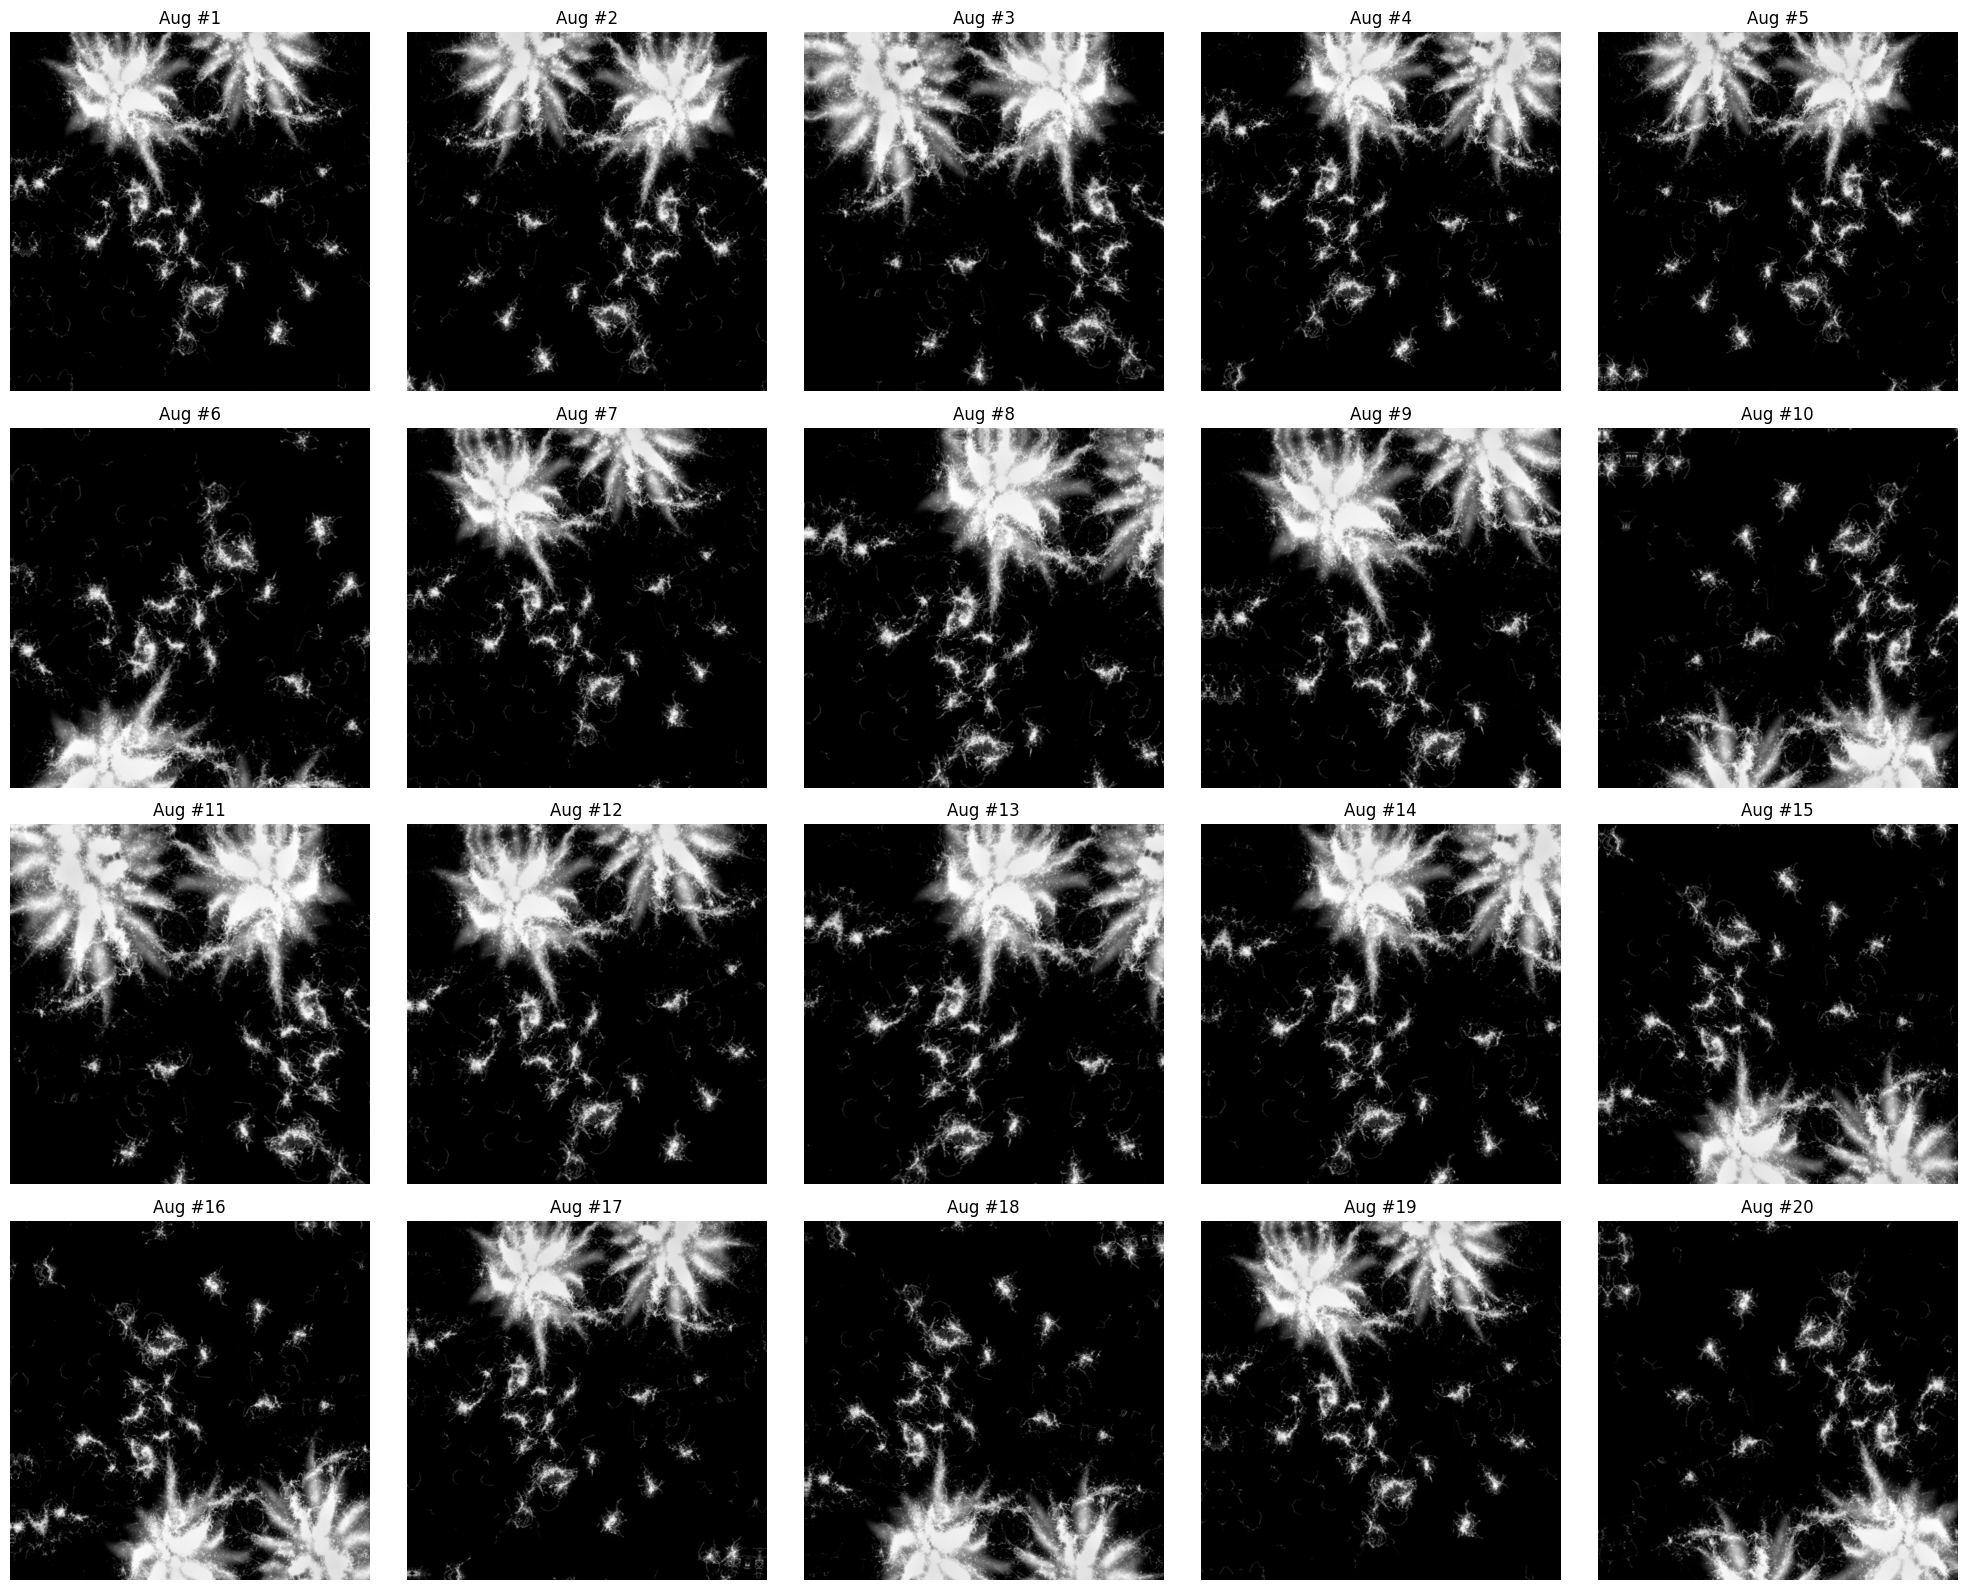

In [2]:
### AUGMENTATION visualize 20 per image ###
# === CONFIG ===
image_path = r".../Imaging data/Cropped_inner_well/AP00424_AnPY_K7 0124 AN_Pr3_24h_2x_3µmZ_XY01_CFW.tif"
RESIZE_SIZE = (1024, 1024)
N_AUGS = 20

# === LOAD 16-bit IMAGE ===
img = io.imread(image_path).astype(np.uint16)
print("Loaded:", img.shape, img.dtype, "min/max:", img.min(), img.max())

# Resize safely in 16-bit
img_resized = transform.resize(
    img, RESIZE_SIZE, order=1, preserve_range=True, anti_aliasing=True
).astype(np.uint16)

# === AUGMENT FUNCTION (stays 16-bit) ===
def gentle_augment_16(img):
    aug = img.copy().astype(np.float32)

    # 1. Small rotation ±20°
    angle = random.uniform(-20, 20)
    aug = transform.rotate(aug, angle=angle, resize=False, mode="reflect", preserve_range=True)

    # 2. Gentle shear ±0.10
    shear = random.uniform(-0.10, 0.10)
    tform = transform.AffineTransform(shear=shear)
    aug = transform.warp(aug, tform, mode="reflect", preserve_range=True)

    # 3. Random flips
    if random.random() < 0.5:
        aug = np.fliplr(aug)
    if random.random() < 0.3:
        aug = np.flipud(aug)

    # 4. Gentle translation ±2%
    tx = random.uniform(-0.02, 0.02) * img.shape[1]
    ty = random.uniform(-0.02, 0.02) * img.shape[0]
    tform = transform.AffineTransform(translation=(tx, ty))
    aug = transform.warp(aug, tform, mode="reflect", preserve_range=True)

    # 5. Gentle zoom (1–1.2×)
    zoom = random.uniform(1, 1.3)
    aug = transform.rescale(aug, zoom, mode="reflect", preserve_range=True, anti_aliasing=True)

    # Crop or pad back to 1024×1024
    h, w = aug.shape
    pad_y = max(0, RESIZE_SIZE[0] - h)
    pad_x = max(0, RESIZE_SIZE[1] - w)
    aug = np.pad(aug, ((pad_y//2, pad_y - pad_y//2), (pad_x//2, pad_x - pad_x//2)), mode="reflect")
    aug = aug[:RESIZE_SIZE[0], :RESIZE_SIZE[1]]

    return np.clip(aug, 0, 65535).astype(np.uint16)

# === GENERATE AND DISPLAY ===
augmented_images = [gentle_augment_16(img_resized) for _ in range(N_AUGS)]

cols = 5
rows = int(np.ceil(N_AUGS / cols))
fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows))
axes = axes.flatten()

for i, aug_np in enumerate(augmented_images):
    axes[i].imshow(aug_np, cmap="gray")
    axes[i].axis("off")
    axes[i].set_title(f"Aug #{i+1}")
    #axes[i].set_title(f"Aug #{i+1}\nmin={aug_np.min():.0f}, max={aug_np.max():.0f}")

for j in range(i + 1, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()


In [126]:
# === CONFIG ===
input_dir = r".../Imaging data/Cropped_inner_well/"
output_dir = os.path.join(input_dir, "Augmented_20")
os.makedirs(output_dir, exist_ok=True)

RESIZE_SIZE = (1024, 1024)
N_AUGS = 20  # number of augmented images per original

# === AUGMENT FUNCTION (16-bit-safe) ===
def gentle_augment_16(img):
    aug = img.copy().astype(np.float32)

    # 1️⃣ Small rotation ±10°
    angle = random.uniform(-10, 10)
    aug = sk_transform.rotate(aug, angle=angle, resize=False, mode="reflect", preserve_range=True)

    # 2️⃣ Gentle shear ±0.05
    shear = random.uniform(-0.05, 0.05)
    tform = sk_transform.AffineTransform(shear=shear)
    aug = sk_transform.warp(aug, tform, mode="reflect", preserve_range=True)

    # 3️⃣ Random flips
    if random.random() < 0.5:
        aug = np.fliplr(aug)
    if random.random() < 0.3:
        aug = np.flipud(aug)

    # 4️⃣ Gentle translation ±2%
    tx = random.uniform(-0.02, 0.02) * img.shape[1]
    ty = random.uniform(-0.02, 0.02) * img.shape[0]
    tform = sk_transform.AffineTransform(translation=(tx, ty))
    aug = sk_transform.warp(aug, tform, mode="reflect", preserve_range=True)

    # 5️⃣ Gentle zoom (0.95–1.3×)
    zoom = random.uniform(0.95, 1.3)
    aug = sk_transform.rescale(aug, zoom, mode="reflect", preserve_range=True, anti_aliasing=True)

    # Crop or pad back to 1024×1024
    h, w = aug.shape
    pad_y = max(0, RESIZE_SIZE[0] - h)
    pad_x = max(0, RESIZE_SIZE[1] - w)
    aug = np.pad(
        aug,
        ((pad_y // 2, pad_y - pad_y // 2), (pad_x // 2, pad_x - pad_x // 2)),
        mode="reflect"
    )
    aug = aug[:RESIZE_SIZE[0], :RESIZE_SIZE[1]]

    return np.clip(aug, 0, 65535).astype(np.uint16)


# === PROCESS ALL IMAGES ===
for filename in tqdm(os.listdir(input_dir)):
    if not filename.lower().endswith((".tif", ".tiff")):
        continue

    in_path = os.path.join(input_dir, filename)
    base_name = os.path.splitext(filename)[0]

    # Load 16-bit image
    img = io.imread(in_path).astype(np.uint16)
    img_resized = sk_transform.resize(
        img, RESIZE_SIZE, order=1, preserve_range=True, anti_aliasing=True
    ).astype(np.uint16)

    # Generate and save augmentations
    for i in range(N_AUGS):
        aug = gentle_augment_16(img_resized)
        out_name = f"{base_name}_aug_{i+1:02d}.tif"
        out_path = os.path.join(output_dir, out_name)
        io.imsave(out_path, aug)

print(f"✅ Done! All augmented images saved in:\n{output_dir}")


100%|██████████| 544/544 [1:13:58<00:00,  8.16s/it]

✅ Done! All augmented images saved in:
H:/Sophie/Dataset/MIP for AI/Cropped/Cropped2/Bioreactor/Augmented_30
